# Trabajo Práctico Nº 1
## Objetivos

- Implementar y analizar el filtro de promedio móvil (moving average) en Python.
- Aplicar el concepto de convolución en señales digitales.
- Familiarizarse con el entorno de desarrollo en Python notebooks.
- Comparar representación en punto flotante vs punto fijo, evaluando precisión y tiempos de cómputo.

# Ejercicio 1 - Filtro Moving Average

1. Implementá un algoritmo de promedio móvil (moving average) según la definición vista en clase, que reciba como parámetros:

- La señal de entrada.
- El tamaño de la ventana.

A partir de tu implementación, obtené y graficá la respuesta impulsiva del sistema (lo que en clase llamamos su “firma” o función de transferencia).

2. Respondé:

- ¿Cómo se obtiene la respuesta impulsiva de cualquier sistema?
- ¿Qué representa en el caso del filtro de promedio móvil?

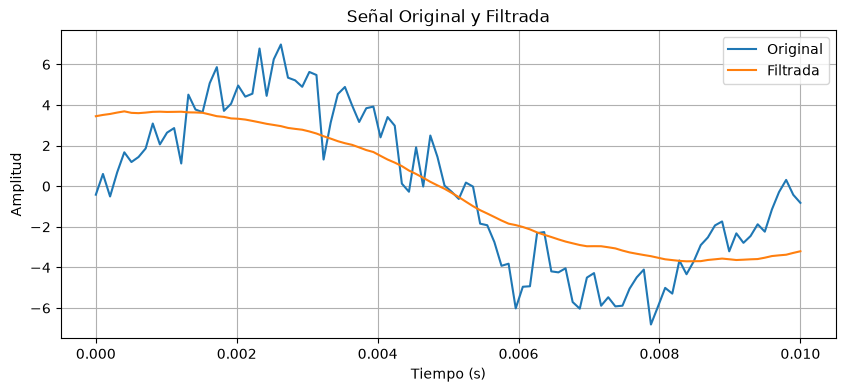

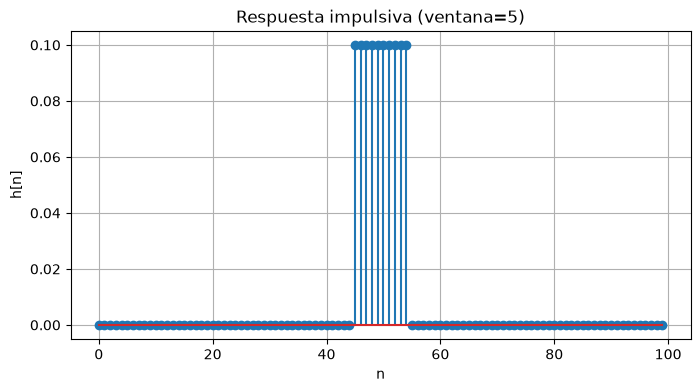

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def moving_average(signal, MVSIZE):
  avg = np.zeros(len(signal))
  for n in range(len(signal)):
    suma = 0
    d = 0
    for k in range (-(MVSIZE), MVSIZE):
        if ((n-k) > 0) and ((n-k) < (len(signal))):
            suma = suma + signal[(n-k)]
            d = d+1
    avg[n] = np.copy(suma/d)
  return avg

Fs = 10000  # Frecuencia de muestreo (Hz)
N = 100      # Número de muestras

t = np.linspace(0,N/Fs,num=N) #Crea una variable de tiempo desde 0, con intervalos de ts=1/Fs
f1 = 100   # Hz
A1 = 5
signal_1 = A1 * np.sin(2*np.pi*f1*t)


ruidosa= signal_1 + np.random.normal(0,1,len(signal_1))
averaged = moving_average(ruidosa, 27)

# Visualizar la señal original y filtrada
plt.figure(figsize=(10, 4))
plt.plot(t, ruidosa, label='Original')
plt.plot(t, averaged, label='Filtrada')
plt.title('Señal Original y Filtrada')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()
plt.grid(True)
plt.show()


def generar_delta_dirac(cantidad, pos):
    if pos >= cantidad:
        return 'Error: posición fuera de rango'
    delta = [0]*cantidad
    delta[pos] = 1
    return delta

# Prueba del impulso unitario
N = 100
MVSIZE = 5

impulso = generar_delta_dirac(N, N//2)

respuesta_impulsiva = moving_average(impulso, MVSIZE)

# Visualizar la señal delta dirac y su filtrado
plt.figure(figsize=(8,4))
plt.stem(respuesta_impulsiva)
plt.title(f'Respuesta impulsiva (ventana={MVSIZE})')
plt.xlabel('n')
plt.ylabel('h[n]')
plt.grid(True)
plt.show()

Para obtener la respuesta impulsiva de cualquier sistema basta con ingresar por la entrada del mismo un impulso unitario,

En el caso del promedio movil representa un rectángulo.

# Ejercicio 2 - Respuesta del sistema

1. Genera dos señales de prueba:
    - Una onda cuadrada de amplitud 1 y frecuencia de 2 kHz.
    - Una onda triangular de amplitud 1 y frecuencia de 1 kHz.

Aplica el moving average implementado en el Ejercicio 1 a estas señales.

2. Analiza los resultados:

    - Grafica la señal original y la señal filtrada.
    - Explica qué cambios observas en la forma de onda.

3. Escribe tus conclusiones: ¿qué efecto tiene el filtro de promedio móvil sobre cada señal?


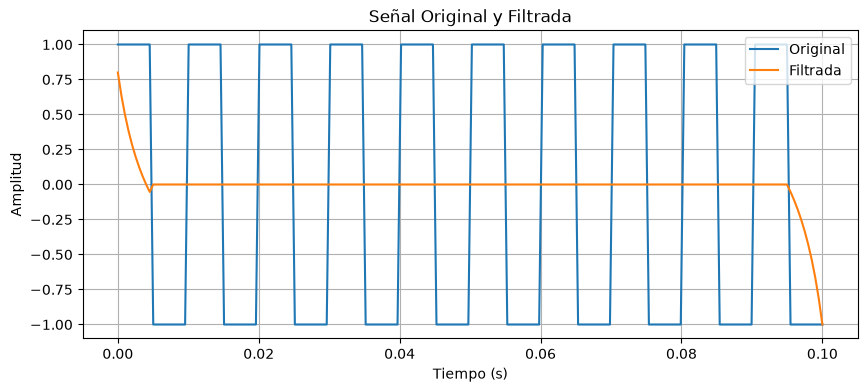

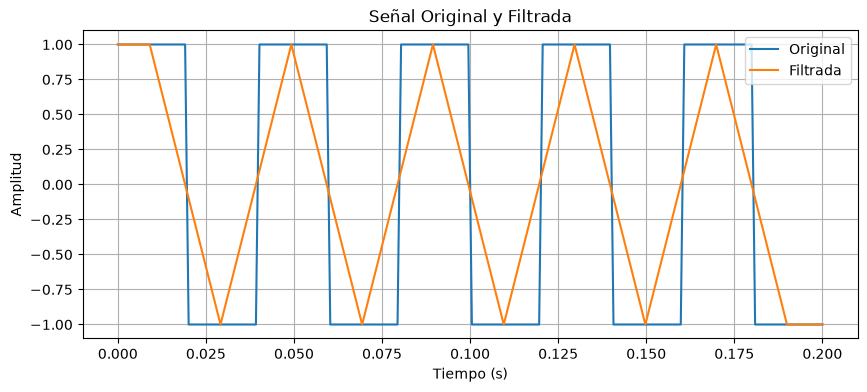

In [13]:
import scipy.signal as sig
import numpy as np
import matplotlib.pyplot as plt

def moving_average(signal, MVSIZE):
  avg = np.zeros(len(signal))
  for n in range(len(signal)):
    suma = 0
    d = 0
    for k in range (-(MVSIZE), MVSIZE):
        if ((n-k) > 0) and ((n-k) < (len(signal))):
            suma = suma + signal[(n-k)]
            d = d+1
    avg[n] = np.copy(suma/d)
  return avg

t_square = np.linspace(0, 1, 200)
f_square_1 = 2000
f_square_2 = 1000
senal_cuad_1= sig.square(2 * np.pi * f_square_1* t_square)
senal_cuad_2= sig.square(2 * np.pi * f_square_2* t_square)
N = 200      # Número de muestras
t_1 = np.linspace(0,N/f_square_1,num=N)
t_2 = np.linspace(0,N/f_square_2,num=N)

respuesta_filtrada_1 = moving_average(senal_cuad_1,10)
respuesta_filtrada_2 = moving_average(senal_cuad_2,10)

plt.figure(figsize=(10, 4))
plt.plot(t_1, senal_cuad_1, label='Original')
plt.plot(t_1, respuesta_filtrada_1, label='Filtrada')
plt.title('Señal Original y Filtrada')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(t_2, senal_cuad_2, label='Original')
plt.plot(t_2, respuesta_filtrada_2, label='Filtrada')
plt.title('Señal Original y Filtrada')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()
plt.grid(True)
plt.show()

# Ejercicio 3 - Convolución en punto flotante y punto fijo

1. Implementa un algoritmo de convolución:

    - En punto flotante (float).
    - En punto fijo, utilizando por ejemplo la librería fixedpoint.

2. Compara los resultados con la función de NumPy np.convolve. Mide y compara:

    - El tiempo de ejecución usando timeit.
    - El error de la salida respecto al cálculo en punto flotante.

3. Graficos:
    - Graficar todas las señales utilizadas   

4. Conclusión:

    - ¿Qué diferencias observas entre las implementaciones?
    - ¿Qué ventajas y desventajas tiene usar punto fijo en lugar de punto flotante?

# Ejercicio 3 - Convolución en punto flotante y punto fijo

1. Implementa un algoritmo de convolución:

    - En punto flotante (float).
    - En punto fijo, utilizando por ejemplo la librería fixedpoint.

In [14]:
!pip install fixedpoint

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\aguil\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [15]:
#1)
#punto fijo

from __future__ import division
import numpy as np
from fixedpoint import FixedPoint

# -----------------------------
# FUNCIONES AUXILIARES
# -----------------------------
def fixedToFloat(array):
    """Convierte un array de FixedPoint a lista de floats."""
    result = []
    for num in array:
        result.append(float(num))
    return result

def arrayFixedPointValue(initial_value, fx_array_len, qformat):
    """Crea un array de punto fijo con initial_value en todas sus posiciones."""
    fx_type = FixedPoint(initial_value, **qformat)
    fx_array = [FixedPoint(initial_value, **qformat) for _ in range(fx_array_len)]
    return fx_array

def arrayFixedPoint(initial_array, qformat):
    """Convierte un array de floats a FixedPoint con formato qformat."""
    fx_array = []
    for num in initial_array:
        fx_num = FixedPoint(num, **qformat)
        fx_array.append(fx_num)
    return fx_array

# -----------------------------
# CONVOLUCIÓN EN PUNTO FIJO
# -----------------------------
def convolucion_fixed(x, h, qformat):
    """Convolución discreta en punto fijo."""
    N = len(x)
    M = len(h)
    y_len = N + M - 1

    # Convertimos entradas a punto fijo
    x_fx = arrayFixedPoint(x, qformat)
    h_fx = arrayFixedPoint(h, qformat)

    # Inicializamos salida en punto fijo
    y_fx = arrayFixedPointValue(0, y_len, qformat)

    for n in range(y_len):
        acc = FixedPoint(0, **qformat)
        for k in range(N):
            if 0 <= n-k < M:
                acc += x_fx[k] * h_fx[n-k]
        y_fx[n] = acc
    return y_fx

# Señales de ejemplo
x = [1.0, 2.05, 3.0]
h = [1.5, -1.0, 2.0]

# Definimos formato Q -> 3 bits enteros + 4 bits fraccionarios
qformat = {'signed': True, 'm': 3, 'n': 20}

# Convolución en fixed
y_fixed = convolucion_fixed(x, h, qformat)
y0 = fixedToFloat(y_fixed)

# Resultados
#print("Resultado punto fijo (FixedPoint):", y_fixed)
print("Convertido a float:", y0)


Convertido a float: [1.5, 2.075000286102295, 4.449999809265137, 1.1000003814697266, 6.0]


In [16]:
#1)
#punto flotante
import numpy as np

def convolucion_float(x, h):
    N = len(x)
    M = len(h)
    y = np.zeros(N + M - 1, dtype=float)

    for n in range(len(y)):
        for k in range(N):
            if 0 <= n-k < M:
                y[n] += x[k] * h[n-k]
    return y

# Ejemplo
x = [1.0, 2.05, 3.0]
h = [1.5, -1.0, 2.0]

y = convolucion_float(x, h)

print(y[0])
print(y[1])
print(y[2])
print(y[3])
print(y[4])

1.5
2.0749999999999997
4.45
1.0999999999999996
6.0


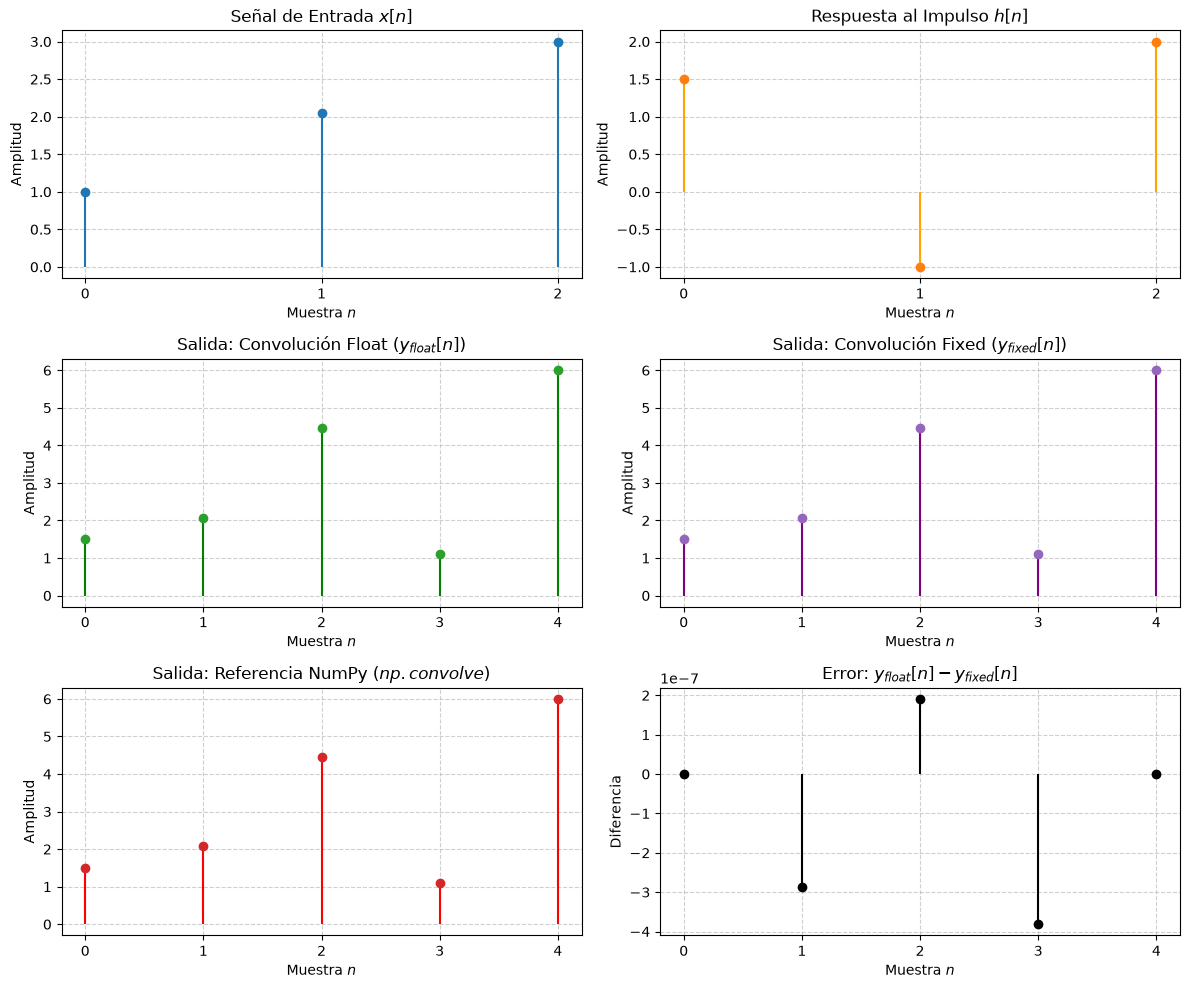

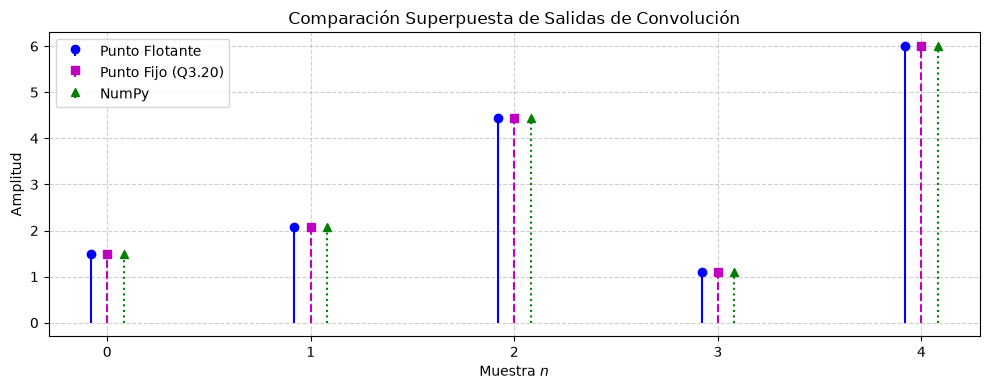

In [17]:
# ==============================================================================
# 3) GRÁFICOS: Graficar todas las señales utilizadas y calculadas
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

# 1. Señales de prueba del ejercicio
x = np.array([1.0, 2.05, 3.0])
h = np.array([1.5, -1.0, 2.0])

# 2. Salidas calculadas de la convolución
y_float = convolucion_float(x, h)
y_fixed = np.array(fixedToFloat(convolucion_fixed(x, h, qformat)))
y_numpy = np.convolve(x, h)
error = y_float - y_fixed

# 3. Asignación para celdas siguientes
y = y_float
y0 = y_fixed.tolist()

n_x = np.arange(len(x))
n_h = np.arange(len(h))
n_y = np.arange(len(y_float))

# ------------------------------------------------------------------------------
# Figura 1: Señales individuales
# ------------------------------------------------------------------------------
plt.figure(figsize=(12, 10))

plt.subplot(3, 2, 1)
plt.stem(n_x, x, basefmt=" ")
plt.title("Señal de Entrada $x[n]$")
plt.xlabel("Muestra $n$")
plt.ylabel("Amplitud")
plt.xticks(n_x)
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(3, 2, 2)
plt.stem(n_h, h, linefmt="orange", markerfmt="C1o", basefmt=" ")
plt.title("Respuesta al Impulso $h[n]$")
plt.xlabel("Muestra $n$")
plt.ylabel("Amplitud")
plt.xticks(n_h)
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(3, 2, 3)
plt.stem(n_y, y_float, linefmt="green", markerfmt="C2o", basefmt=" ")
plt.title("Salida: Convolución Float ($y_{float}[n]$)")
plt.xlabel("Muestra $n$")
plt.ylabel("Amplitud")
plt.xticks(n_y)
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(3, 2, 4)
plt.stem(n_y, y_fixed, linefmt="purple", markerfmt="C4o", basefmt=" ")
plt.title("Salida: Convolución Fixed ($y_{fixed}[n]$)")
plt.xlabel("Muestra $n$")
plt.ylabel("Amplitud")
plt.xticks(n_y)
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(3, 2, 5)
plt.stem(n_y, y_numpy, linefmt="red", markerfmt="C3o", basefmt=" ")
plt.title("Salida: Referencia NumPy ($np.convolve$)")
plt.xlabel("Muestra $n$")
plt.ylabel("Amplitud")
plt.xticks(n_y)
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(3, 2, 6)
plt.stem(n_y, error, linefmt="black", markerfmt="ko", basefmt=" ")
plt.title("Error: $y_{float}[n] - y_{fixed}[n]$")
plt.xlabel("Muestra $n$")
plt.ylabel("Diferencia")
plt.xticks(n_y)
plt.ticklabel_format(axis="y", style="scientific", scilimits=(0, 0))
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Figura 2: Superposición comparativa
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 4))
offset = 0.08
plt.stem(n_y - offset, y_float, linefmt="b-", markerfmt="bo", label="Punto Flotante", basefmt=" ")
plt.stem(n_y, y_fixed, linefmt="m--", markerfmt="ms", label="Punto Fijo (Q3.20)", basefmt=" ")
plt.stem(n_y + offset, y_numpy, linefmt="g:", markerfmt="g^", label="NumPy", basefmt=" ")

plt.title("Comparación Superpuesta de Salidas de Convolución")
plt.xlabel("Muestra $n$")
plt.ylabel("Amplitud")
plt.xticks(n_y)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


2. Compara los resultados con la función de NumPy np.convolve. Mide y compara:

    - El tiempo de ejecución usando timeit.
    - El error de la salida respecto al cálculo en punto flotante.

In [18]:
# 2)
# %pylab inline
import timeit
import time
import numpy as np

# METODO 2 de medición de tiempos
start = time.time()
conv_r = convolucion_float(x,h)
end = time.time()
print ("punto flotante",(end-start)*100000)

start = time.time()
y_fixed = convolucion_fixed(x, h, qformat)
end = time.time()
print ("punto fijo",(end-start)*100000)

start = time.time()
conv_r = np.convolve(x, h)
end = time.time()
print ("numpy",(end-start)*100000)


print(y-y0)


punto flotante 0.0
punto fijo 102.49614715576172
numpy 0.0
[ 0.00000000e+00 -2.86102295e-07  1.90734863e-07 -3.81469727e-07
  0.00000000e+00]


3)Conclusión:
¿Qué diferencias observas entre las implementaciones?

La principal diferencia entre punto fijo y punto flotante está en el tiempo de ejecución y la precisión. El punto fijo es más rápido de implementar, consume menos recursos y energía, lo que lo hace ideal para sistemas en tiempo real. Sin embargo, sacrifica precisión.

El punto flotante, en cambio, ofrece mucha más precisión, pero requiere más memoria, mayor potencia de cómputo y un costo de hardware más alto, además de ser más complejo de desarrollar.

¿Qué ventajas y desventajas tiene usar punto fijo en lugar de punto flotante?

El punto fijo tiene como ventajas un menor consumo de recursos de software y hardware, menor uso de memoria y energía, y mejor desempeño en aplicaciones en tiempo real. Sin embargo, su desventaja es menor precisión en comparación con el punto flotante, que brinda mayor exactitud aunque con mayor costo, complejidad y consumo de recursos.


In [19]:
# Ejemplos de medicion de tiempos
# %pylab inline
import timeit
import time
import numpy as np

t = np.arange(0, 1024/20000, 1/20000)
s1= np.sin(2*np.pi*1000*t)+1
s2 = np.sin(2*np.pi*1200*t)

# METODO 1 de medición de tiempos

# Este wrapper empaqueta funciones para que el timeit pueda medir solo eso
def wrapper(func, *args):
    def wrapped():
        return func(*args)
    return wrapped

conv = wrapper(np.convolve, s1, s2)
print (timeit.timeit(conv, number=1))

# METODO 2 de medición de tiempos
start = time.time()
conv_r = np.convolve(s1,s2)
end = time.time()
print (end-start)

0.00023880001390352845
0.0006806850433349609
